# 01. Обзор продаж

Как растёт магазин: GMV и выручка, число заказов, средний чек, недельная сезонность и структура продаж по категориям.

**Данные:** `marts.mart_sales_daily` (продажи по дням), `marts.fct_orders`, `marts.fct_order_items`.
**Определения** (заданы в dbt, см. `dbt/dbt_project.yml`):
- *GMV* - сумма всех оформленных заказов, включая отменённые;
- *выручка* - сумма заказов в статусах `paid`, `shipped`, `delivered`;
- *средний чек* - выручка / число оплаченных заказов;
- *дата заказа* - дата создания в часовом поясе `Europe/Moscow`.

Суммы - в долларах (валюта цен магазина); пересчёт в рубли по курсу ЦБ появится на этапе 4.

In [1]:
import sys
sys.path.insert(0, "..")  # модуль analytics лежит в корне репозитория

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analytics.db import query
from analytics.plots import setup, money_axis, percent_axis, BLUE, ORANGE, AQUA, YELLOW, GRAY, SERIES

setup()
pd.set_option("display.float_format", "{:,.2f}".format)

## Данные

Берём только полные дни (`is_complete_period`) и отрезаем последний день с заказами: история заканчивается посреди дня, а без генератора следующие дни выглядели бы как обвал продаж.

In [2]:
daily = query("""
    select *
    from mart_sales_daily
    where is_complete_period
      and date < (select max(order_date) from fct_orders)
    order by date
""")
experiment_start = query("select min(window_start) as ts from mart_ab_users").ts[0]

print(f"Период: {daily.date.min():%d.%m.%Y} - {daily.date.max():%d.%m.%Y}, {len(daily)} дней")
print(f"Старт A/B-эксперимента со скидкой: {experiment_start:%d.%m.%Y}")

Период: 02.05.2026 - 28.10.2026, 180 дней
Старт A/B-эксперимента со скидкой: 17.09.2026


In [3]:
total = daily[["orders", "paid_orders", "cancelled_orders", "gmv", "revenue", "units_sold"]].sum()
pd.DataFrame({
    "Показатель": ["Заказов", "Оплаченных заказов", "Отменённых заказов", "GMV", "Выручка",
                   "Выручка / GMV", "Средний чек", "Товаров продано"],
    "Значение": [f"{total.orders:,.0f}", f"{total.paid_orders:,.0f}", f"{total.cancelled_orders:,.0f}",
                 f"{total.gmv:,.0f}", f"{total.revenue:,.0f}", f"{total.revenue / total.gmv:.1%}",
                 f"{total.revenue / total.paid_orders:,.0f}", f"{total.units_sold:,.0f}"],
}).set_index("Показатель")

,Значение
Показатель,
Заказов,"16,531"
Оплаченных заказов,"14,074"
Отменённых заказов,"2,445"
GMV,"14,791,011"
Выручка,"12,605,039"
Выручка / GMV,85.2%
Средний чек,896
Товаров продано,"70,182"


## Динамика по неделям

Дневной ряд шумный и содержит недельную сезонность, поэтому смотрим на недели (пн-вс). Неполные недели по краям периода отбрасываем, иначе первая и последняя точки покажут ложный спад.

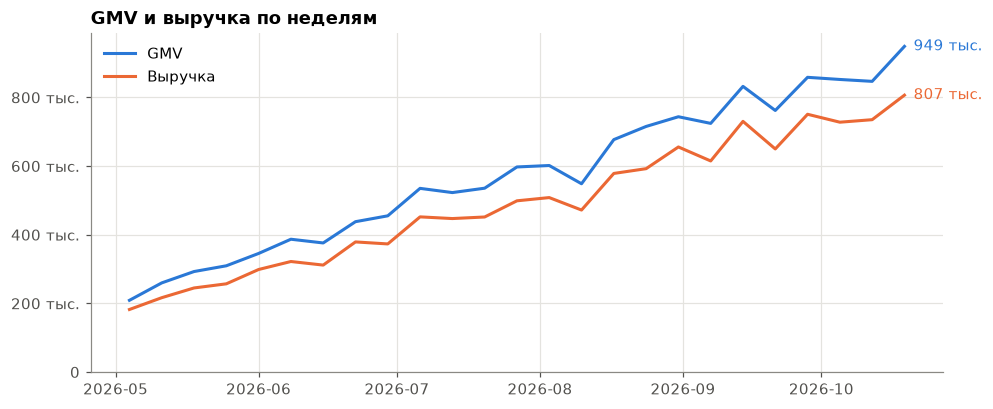

In [4]:
by_week = daily.set_index("date").resample("W-MON", label="left", closed="left")
weekly = by_week[["orders", "paid_orders", "gmv", "revenue"]].sum()
weekly = weekly[by_week.size() == 7]
weekly["aov"] = weekly.revenue / weekly.paid_orders

fig, ax = plt.subplots()
ax.plot(weekly.index, weekly.gmv, label="GMV", color=BLUE)
ax.plot(weekly.index, weekly.revenue, label="Выручка", color=ORANGE)
ax.set_title("GMV и выручка по неделям")
money_axis(ax)
ax.set_ylim(bottom=0)
ax.legend(loc="upper left")
for name, color in [("GMV", BLUE), ("Выручка", ORANGE)]:
    col = "gmv" if name == "GMV" else "revenue"
    ax.annotate(f"{weekly[col].iloc[-1] / 1e3:.0f} тыс.", (weekly.index[-1], weekly[col].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color=color)
plt.show()

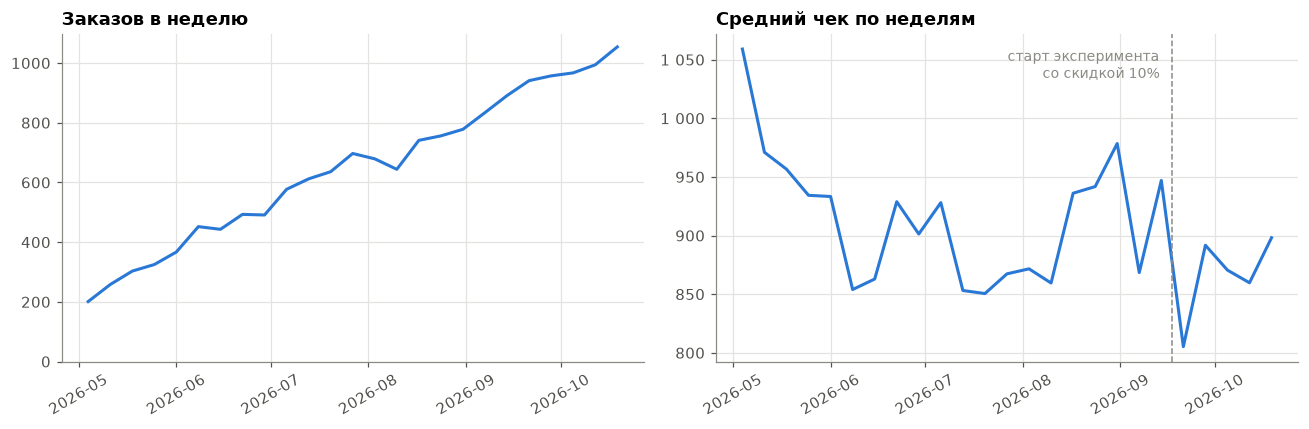

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(weekly.index, weekly.orders, color=BLUE)
ax1.set_title("Заказов в неделю")
ax1.set_ylim(bottom=0)

ax2.plot(weekly.index, weekly.aov, color=BLUE)
ax2.axvline(experiment_start, color=GRAY, linestyle="--", linewidth=1)
ax2.annotate("старт эксперимента\nсо скидкой 10%", (experiment_start, weekly.aov.max()),
             xytext=(-8, 0), textcoords="offset points", ha="right", va="top", color=GRAY, fontsize=9)
ax2.set_title("Средний чек по неделям")
money_axis(ax2)
for ax in (ax1, ax2):
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [6]:
# рост: последние 4 полные недели против 4 предыдущих
def period(w):
    return pd.Series({"Заказы": w.orders.sum(), "Выручка": w.revenue.sum(),
                      "Средний чек": w.revenue.sum() / w.paid_orders.sum()})

growth = pd.DataFrame({"Предыдущие 4 недели": period(weekly.iloc[-8:-4]),
                       "Последние 4 недели": period(weekly.iloc[-4:])})
growth["Изменение"] = growth.iloc[:, 1] / growth.iloc[:, 0] - 1
growth.style.format({"Предыдущие 4 недели": "{:,.0f}", "Последние 4 недели": "{:,.0f}", "Изменение": "{:+.1%}"})

,Предыдущие 4 недели,Последние 4 недели,Изменение
Заказы,"3,444","3,972",+15.3%
Выручка,"2,650,361","3,020,189",+14.0%
Средний чек,897,880,-1.8%


## Недельная сезонность

Чтобы рост бизнеса не смешивался с сезонностью, считаем индекс дня недели: заказы дня, делённые на среднее за ту же неделю. Индекс 1.10 означает «на 10% больше среднего дня этой недели». Интервал - 95% по разбросу между неделями.

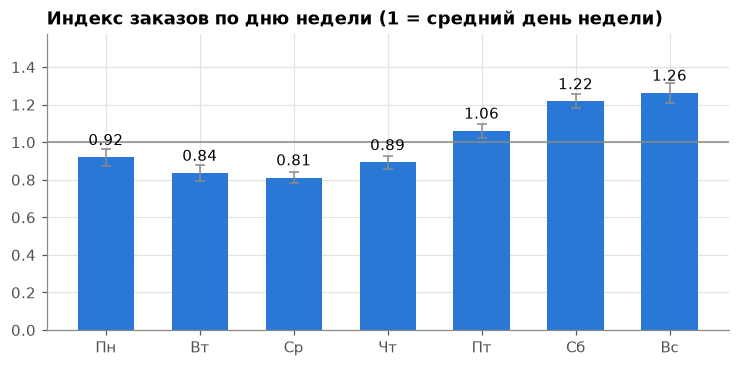

,mean,sem
Пн,0.92,0.02
Вт,0.84,0.02
Ср,0.81,0.02
Чт,0.89,0.02
Пт,1.06,0.02
Сб,1.22,0.02
Вс,1.26,0.03


In [7]:
d = daily.assign(week=daily.date.dt.to_period("W-SUN"))
d = d.groupby("week").filter(lambda g: len(g) == 7)
d["index"] = d.orders / d.groupby("week").orders.transform("mean")
season = d.groupby("day_of_week")["index"].agg(["mean", "sem"])
season.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(season.index, season["mean"], yerr=1.96 * season["sem"], color=BLUE, width=0.6,
       error_kw={"ecolor": GRAY, "capsize": 3, "linewidth": 1})
ax.axhline(1, color=GRAY, linewidth=1)
for x, v in zip(season.index, season["mean"]):
    ax.annotate(f"{v:.2f}", (x, v), xytext=(0, 8), textcoords="offset points", ha="center")
ax.set_title("Индекс заказов по дню недели (1 = средний день недели)")
ax.set_ylim(0, season["mean"].max() * 1.25)
plt.show()
season.round(3)

## Распределение суммы заказа

Средний чек - среднее, а распределение сумм заказов скошено вправо: несколько дорогих заказов (ноутбук стоит как сотня книг) тянут среднее вверх. Для «типичного» заказа честнее медиана; для расчёта выручки - среднее.

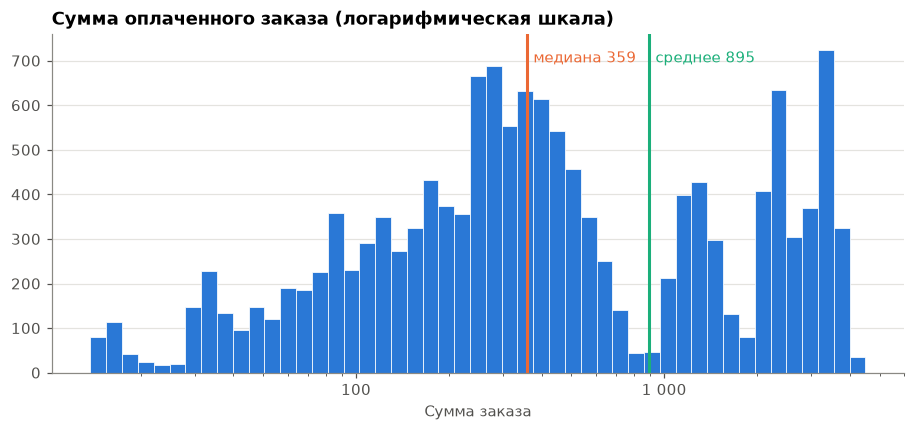

Среднее 895, медиана 359, коэффициент асимметрии 1.37


In [8]:
paid = query("select order_total from fct_orders where is_revenue")
mean, median = paid.order_total.mean(), paid.order_total.median()

fig, ax = plt.subplots()
bins = np.logspace(np.log10(paid.order_total.min()), np.log10(paid.order_total.max()), 50)
ax.hist(paid.order_total, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
money_axis(ax, axis="x")
for value, label, color in [(median, "медиана", ORANGE), (mean, "среднее", AQUA)]:
    ax.axvline(value, color=color, linewidth=2)
    ax.annotate(f"{label} {value:,.0f}", (value, ax.get_ylim()[1] * 0.95), xytext=(4, 0),
                textcoords="offset points", color=color, va="top")
ax.set_title("Сумма оплаченного заказа (логарифмическая шкала)")
ax.set_xlabel("Сумма заказа")
ax.grid(axis="x", visible=False)
plt.show()
print(f"Среднее {mean:,.0f}, медиана {median:,.0f}, коэффициент асимметрии {paid.order_total.skew():.2f}")

## Категории

Выручка по позициям оплаченных заказов (цена на момент покупки).

In [9]:
cat = query("""
    select
        category,
        sum(line_total) as revenue,
        sum(quantity) as units,
        uniqExact(order_id) as orders
    from fct_order_items
    where is_revenue
    group by category
    order by revenue desc
""")
cat["share"] = cat.revenue / cat.revenue.sum()
cat["avg_unit_price"] = cat.revenue / cat.units
cat.set_index("category").style.format(
    {"revenue": "{:,.0f}", "units": "{:,.0f}", "orders": "{:,.0f}", "share": "{:.1%}", "avg_unit_price": "{:,.2f}"})

,revenue,units,orders,share,avg_unit_price
category,,,,,
electronics,"10,219,208","17,379","7,474",81.0%,588.02
home,"1,045,759","17,627","7,561",8.3%,59.33
sport,"932,248","17,724","7,613",7.4%,52.60
books,"417,909","17,535","7,549",3.3%,23.83


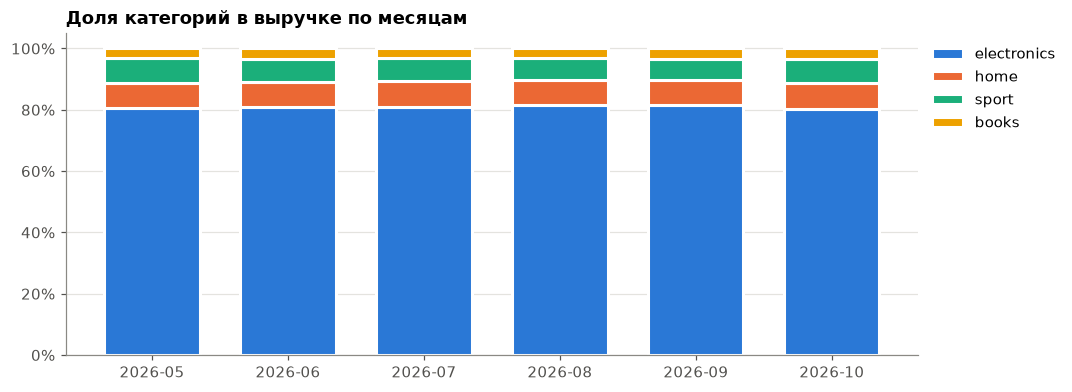

In [10]:
monthly = query("""
    select toStartOfMonth(order_date) as month, category, sum(line_total) as revenue
    from fct_order_items
    where is_revenue
    group by month, category
""").pivot(index="month", columns="category", values="revenue").fillna(0)
monthly = monthly[cat.category]                       # порядок категорий = по выручке, цвета фиксированы
share = monthly.div(monthly.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 3.8))
bottom = np.zeros(len(share))
labels = share.index.strftime("%Y-%m")
for (name, values), color in zip(share.items(), SERIES):
    ax.bar(labels, values, bottom=bottom, label=name, color=color, width=0.7, edgecolor="white", linewidth=2)
    bottom += values.values
percent_axis(ax)
ax.set_title("Доля категорий в выручке по месяцам")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.grid(axis="x", visible=False)
plt.show()

## Выводы

*Данные синтетические (`backfill.py`, seed 42): цифры описывают модель магазина, а ценность ноутбука - в методике.*

1. **Масштаб.** За 180 дней (02.05-28.10.2026) - 16.5 тыс. заказов, GMV 14.8 млн, выручка 12.6 млн. Выручка составляет 85% GMV: остальное - отменённые и ещё не оплаченные заказы. Средний чек - 896.
2. **Рост.** Заказов в неделю стало в ~5 раз больше (с ~200 до ~1 050). Последние 4 недели к предыдущим четырём: заказы +15.3%, выручка +14.0%.
3. **Средний чек** держался в коридоре 850-950 и за последние 4 недели снизился на 1.8%. Часть снижения - эксперимент: с 17.09 половина клиентов покупает со скидкой 10%. Тренд среднего чека после старта эксперимента нельзя читать по всем клиентам - только по группе control (ноутбук 05).
4. **Недельная сезонность.** Пик - выходные (Сб 1.22, Вс 1.26 от среднего дня недели), минимум - середина недели (Ср 0.81): разница пика и дна около 55%. Практический вывод: промо и рассылки - в четверг-пятницу, перед пиком; складу и поддержке - усиление на выходные.
5. **Сумма заказа сильно скошена:** медиана 359 против среднего 895. Для отчётности средний чек годится, но в A/B-тестах денежные метрики будут шумными - понадобятся бутстреп и CUPED.
6. **Концентрация выручки:** электроника даёт 81% выручки при четверти проданных штук, и доля стабильна по месяцам. Выручка магазина зависит от одной категории - это риск (поставщик, цены, сезон в электронике).